# Radiation motion errors

The question here is how much a small error in position can change a dose estimate. I start with motion whose exact answer is known, add synthetic sensor noise, then compare the reconstructed position, dose, and biological response.

All samples and biological parameters in this notebook are illustrative. There are no patient measurements. The main code is in `physics.py`, `methods.py`, and `run_analysis.py`; this notebook works through the pieces and keeps the outputs visible.

Run the cells in order from this folder. `python -m pip install -r requirements-notebook.txt` installs the notebook requirements.

In [1]:
import json
import csv
from pathlib import Path
import numpy as np
from IPython.display import Image, display

from physics import CONFIG, motion, oscillator, dose_rate, accumulated_dose
from physics import survival, repair_system, repair_exact
from methods import divided_differences, newton_value, reconstruct
from methods import central_differences, gmres_steps
from run_analysis import main

# Rebuild the data and figures from the fixed random seeds.
report = main()
root = Path.cwd()

linear         position RMSE 0.2020 mm; dose RMSE 0.025858 Gy
local newton   position RMSE 0.0958 mm; dose RMSE 0.006266 Gy
cubic          position RMSE 0.1042 mm; dose RMSE 0.006799 Gy
GMRES relative residual: 8.242e-13
One-step ODE relative error: 8.842e-02
Figures and tables saved next to this script.


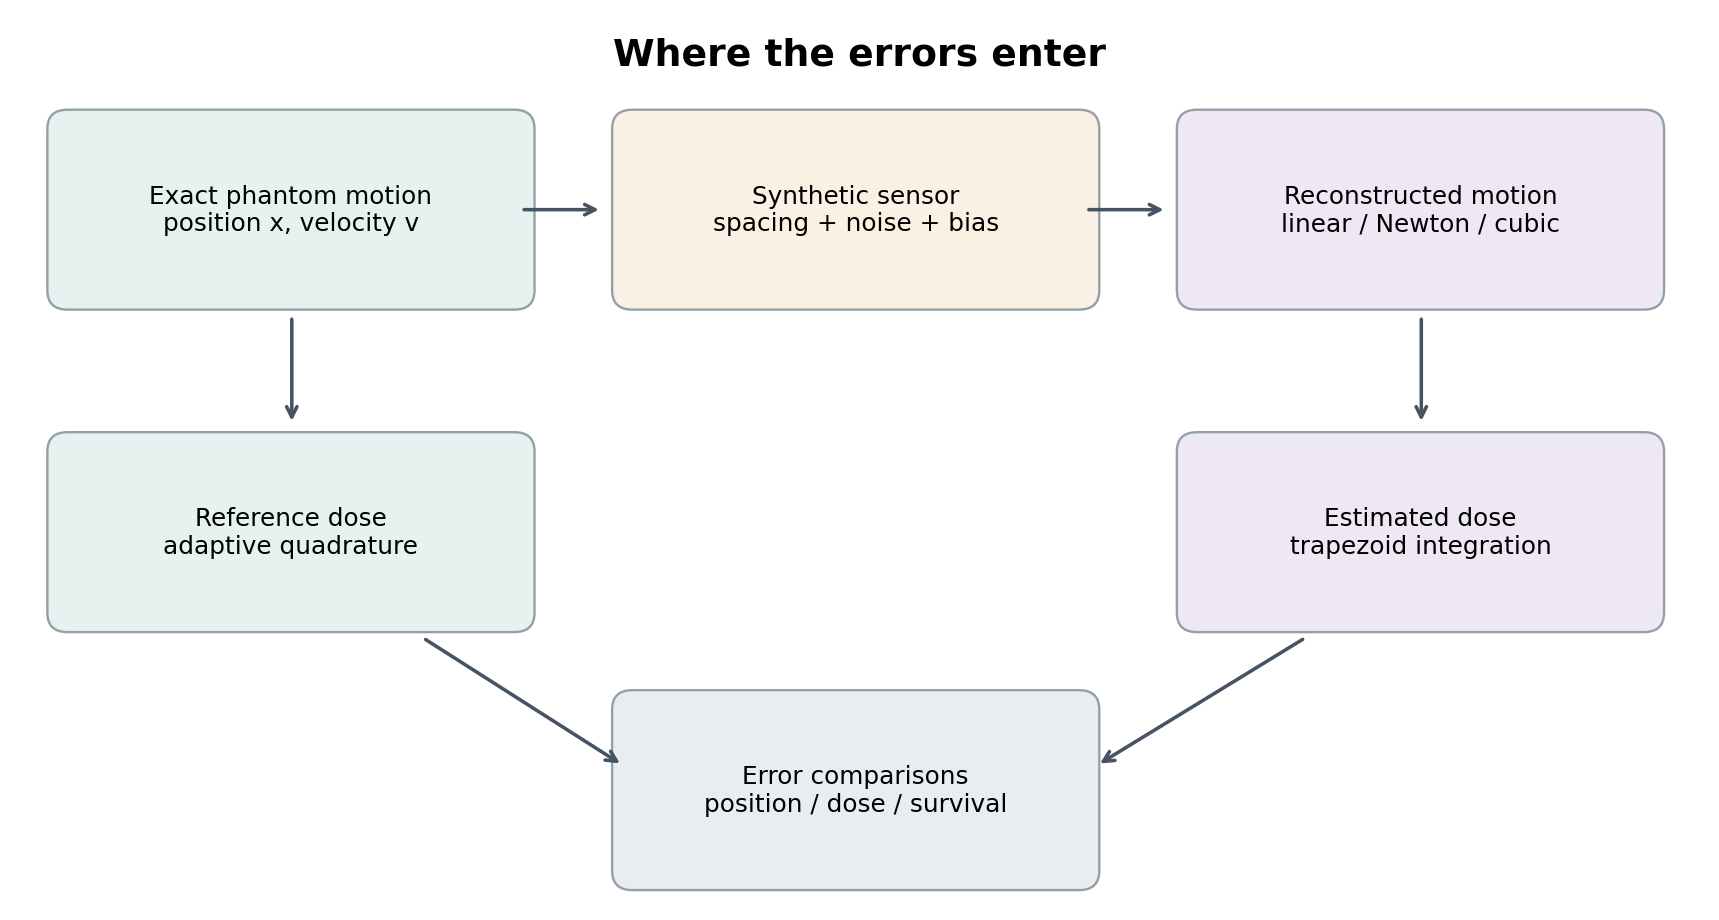

In [2]:
display(Image(filename=str(root / "figures" / "model.png")))

## 1. Start with Newton's law

The phantom has separate position and velocity states: $x'=v$ and $v'=-\omega^2x$. The exact position is $x(t)=4\cos(\omega t)$ mm with $\omega=2\pi/4$ rad/s. It is a controlled oscillator, not a claim that tissue obeys this exact motion.

The force calculation needs metres. The conversion from mm to m is easy to miss.

In [3]:
t = np.array([0.0, 0.5, 1.0, 1.5, 2.0])
x, v, a = motion(t)

mass = CONFIG["mass_kg"]
w = 2 * np.pi / CONFIG["period_s"]
k = mass * w ** 2
force = mass * a / 1000.0
spring_force = -k * x / 1000.0

print("t (s)   x (mm)    v (mm/s)    a (mm/s2)    force (N)")
for i in range(len(t)):
    print("%.1f     %7.3f   %9.3f   %10.3f   %10.6f" % (t[i], x[i], v[i], a[i], force[i]))
print("Largest Newton-law mismatch:", np.max(np.abs(force - spring_force)))

t (s)   x (mm)    v (mm/s)    a (mm/s2)    force (N)
0.0       4.000      -0.000       -9.870    -0.009870
0.5       2.828      -4.443       -6.979    -0.006979
1.0       0.000      -6.283       -0.000    -0.000000
1.5      -2.828      -4.443        6.979     0.006979
2.0      -4.000      -0.000        9.870     0.009870
Largest Newton-law mismatch: 0.0


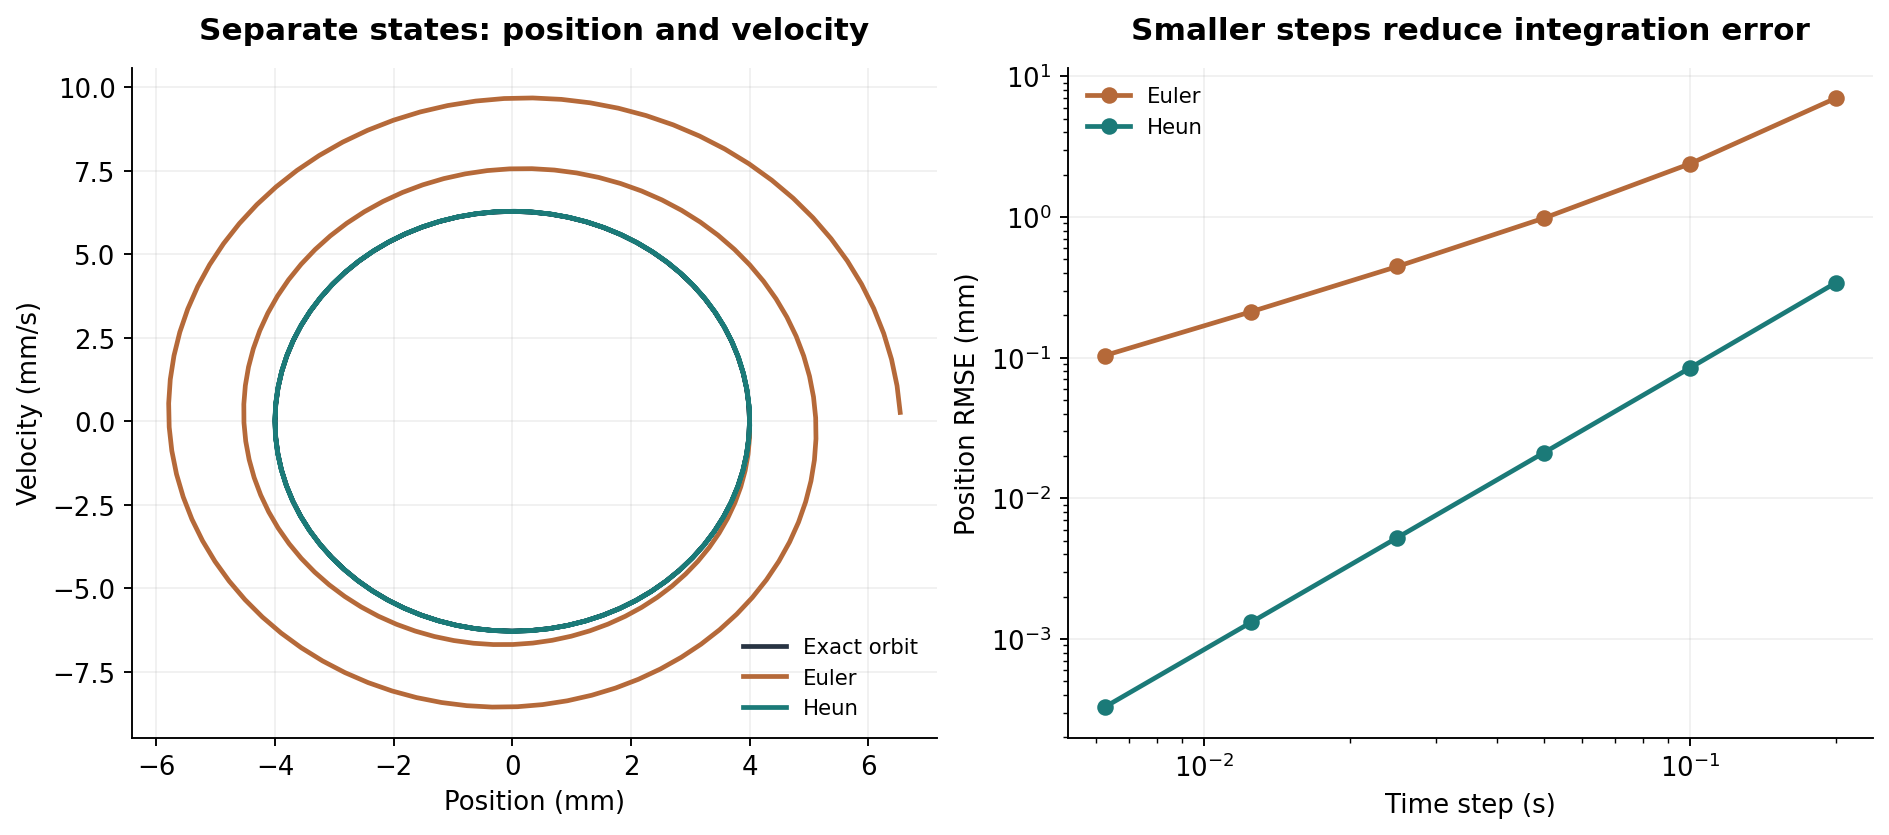

In [4]:
display(Image(filename=str(root / "figures" / "newtonian_states.png")))

Euler's phase curve moves away from the exact orbit: numerical integration is adding energy. Heun is more accurate here, but it is not an energy-preserving method either. The convergence CSV checks the effect of halving the time step.

## 2. Reconstruct the missing positions

Newton interpolation uses divided differences to form $p(t)=c_0+c_1(t-t_0)+c_2(t-t_0)(t-t_1)+\cdots$. This example uses only four nearby samples, giving a cubic. The full experiment compares that local approach with linear interpolation and a natural cubic spline.

The division in a divided difference estimates how a previous difference changes over a wider interval. Nested multiplication evaluates the polynomial without expanding all its powers.

In [5]:
nodes = np.array([0.0, 0.5, 1.0, 1.5])
values = motion(nodes)[0]
c = divided_differences(nodes, values)
q = np.array([0.25, 0.75, 1.25])
p = newton_value(nodes, c, q)
true = motion(q)[0]

print("Divided-difference coefficients:", np.round(c, 6))
for i in range(len(q)):
    print("t = %.2f, interpolated = %.4f, exact = %.4f, error = %.4f" % (q[i], p[i], true[i], p[i] - true[i]))

Divided-difference coefficients: [ 4.       -2.343146 -3.313708  2.209139]
t = 0.25, interpolated = 3.7249, exact = 3.6955, error = 0.0294
t = 0.75, interpolated = 1.5178, exact = 1.5307, error = -0.0130
t = 1.25, interpolated = -1.5178, exact = -1.5307, error = 0.0130


Method         position RMSE   interior RMSE   dose RMSE
linear         0.201955 mm    0.191703 mm     0.025858 Gy
local newton   0.095767 mm    0.096742 mm     0.006266 Gy
cubic          0.104168 mm    0.097224 mm     0.006799 Gy


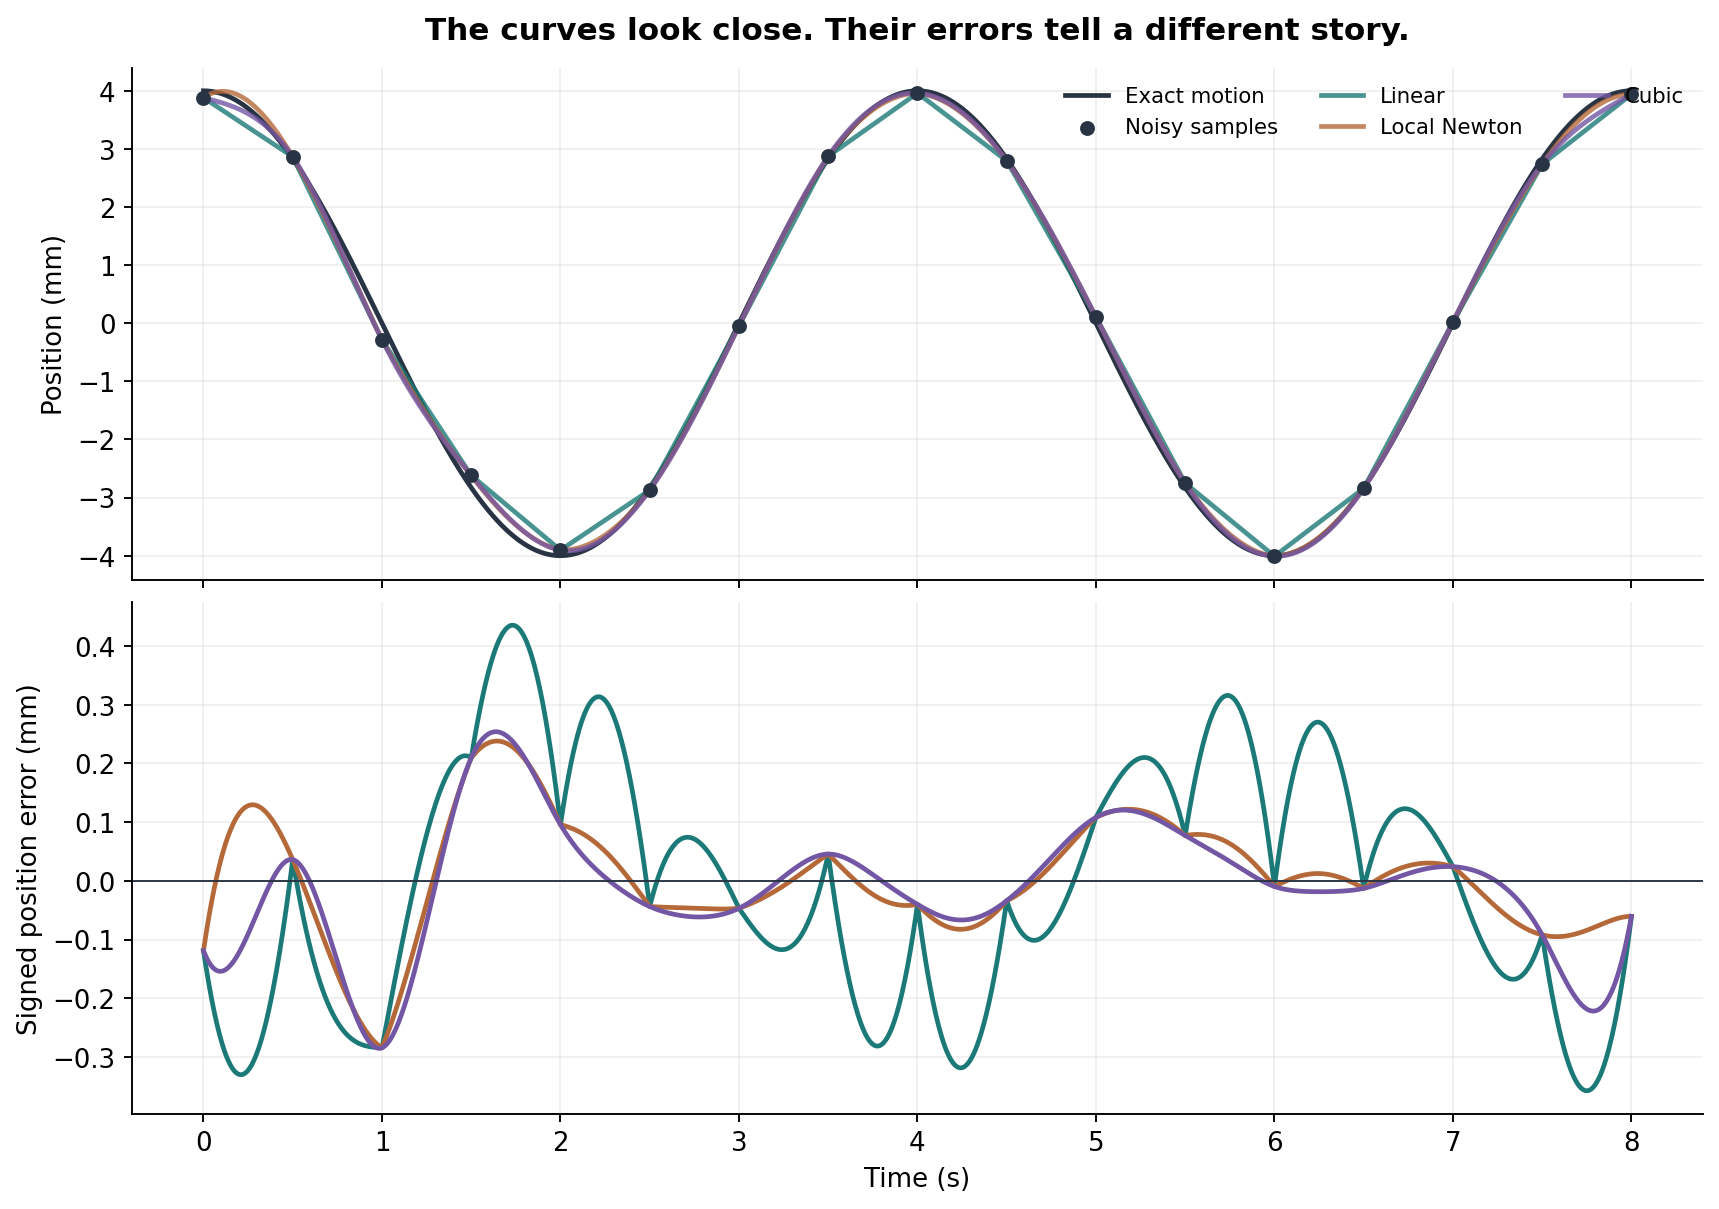

In [6]:
display(Image(filename=str(root / "figures" / "motion_reconstruction.png")))

print("Method         position RMSE   interior RMSE   dose RMSE")
for row in report["methods"]:
    print("%-14s %.6f mm    %.6f mm     %.6f Gy" % (
        row["method"], row["position_rmse_mm"],
        row["interior_position_rmse_mm"], row["dose_rmse_gy"]))

The natural spline assumes zero endpoint acceleration. That conflicts with this cosine motion, so the table also excludes one sampling interval from each end. Local Newton is continuous at the sample times, but neighboring cubic pieces need not have matching derivatives.

These methods all interpolate measurements, including their noise. Interpolation is not smoothing.

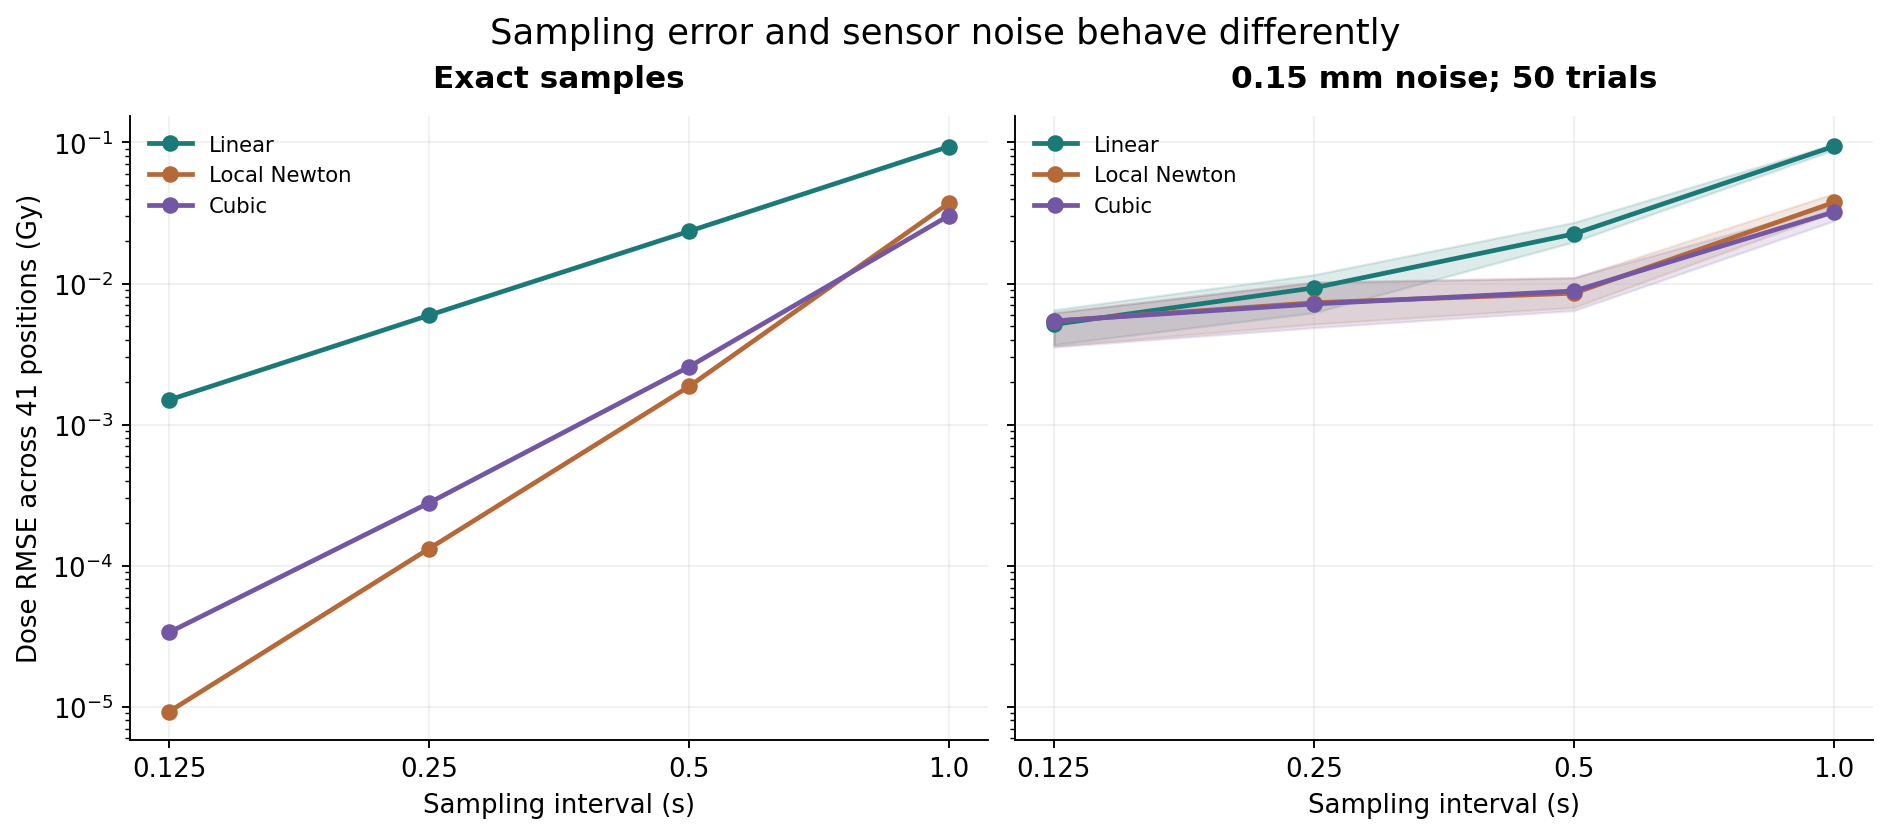

In [7]:
display(Image(filename=str(root / "figures" / "sampling_and_noise.png")))

The shaded regions are the middle 50% of trial errors, not confidence intervals for clinical performance. All methods receive the same noise realization within each trial. The clean case is run once because there is no random noise to repeat.

## 3. Differentiate carefully

For the central formulas, $v_i\approx(x_{i+1}-x_{i-1})/(2h)$ and $a_i\approx(x_{i+1}-2x_i+x_{i-1})/h^2$. This function returns only interior values; it does not invent endpoint derivatives.

In [8]:
t = np.linspace(0, 2, 9)
x = motion(t)[0]
inside, v_est, a_est = central_differences(t, x)
true_x, true_v, true_a = motion(inside)

print("t       velocity error      acceleration error")
for i in range(len(inside)):
    print("%.2f      % .5f             % .5f" % (
        inside[i], v_est[i] - true_v[i], a_est[i] - true_a[i]))

sigma = 0.15
for h in [0.5, 0.25, 0.125]:
    sd = np.sqrt(6) * sigma / h ** 2
    print("h = %.3f s, acceleration noise SD = %.4f mm/s2" % (h, sd))

t       velocity error      acceleration error
0.25       0.06133              0.11658
0.50       0.11331              0.08923
0.75       0.14805              0.04829
1.00       0.16025              0.00000
1.25       0.14805             -0.04829
1.50       0.11331             -0.08923
1.75       0.06133             -0.11658
h = 0.500 s, acceleration noise SD = 1.4697 mm/s2
h = 0.250 s, acceleration noise SD = 5.8788 mm/s2
h = 0.125 s, acceleration noise SD = 23.5151 mm/s2


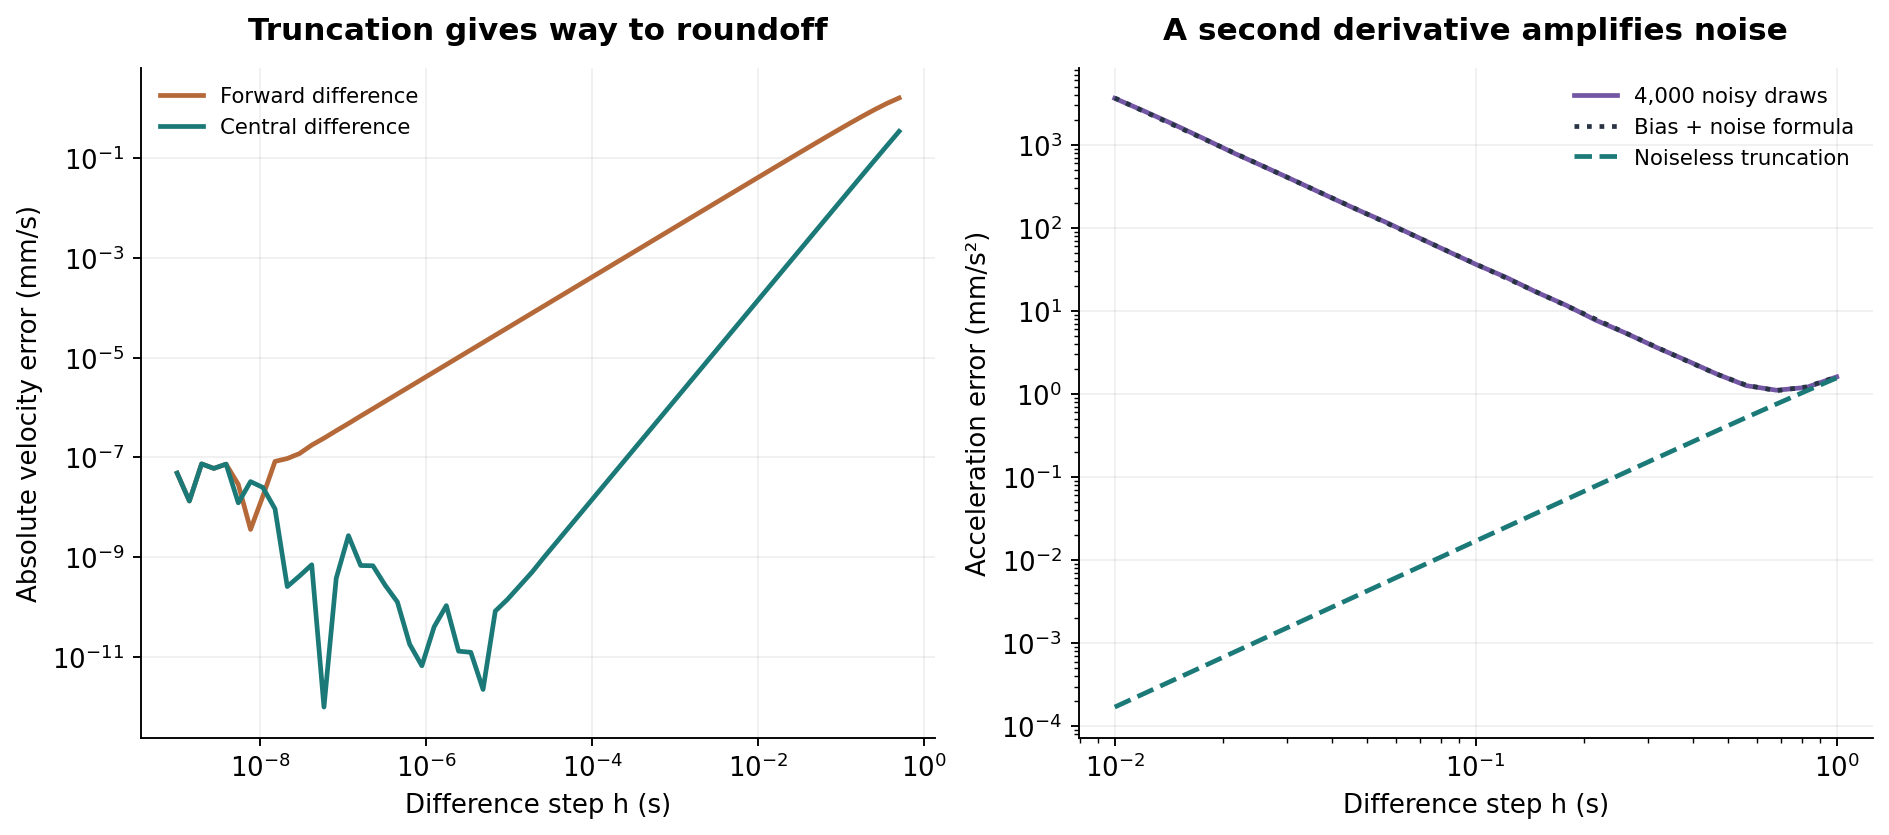

In [9]:
display(Image(filename=str(root / "figures" / "differentiation.png")))

Taking smaller differences reduces truncation error only up to a point. With noisy positions, the acceleration noise grows like 1/h². In the noiseless calculation, very small steps also suffer floating-point cancellation. Those are different error sources.

## 4. Accumulate dose along a material point

A point fixed in the phantom has reference coordinate $r$. In the beam's coordinates it is at $r+x(t)$, so $D(r)=\int q(r+x(t))dt$. The assumed field is smooth and flat in the middle, with softer edges. Motion matters most where the field changes with position.

r = 0.0 mm, stationary = 2.4922 Gy, moving = 2.4747 Gy
r = 6.0 mm, stationary = 1.8629 Gy, moving = 1.4691 Gy
r = 10.0 mm, stationary = 0.0567 Gy, moving = 0.5279 Gy


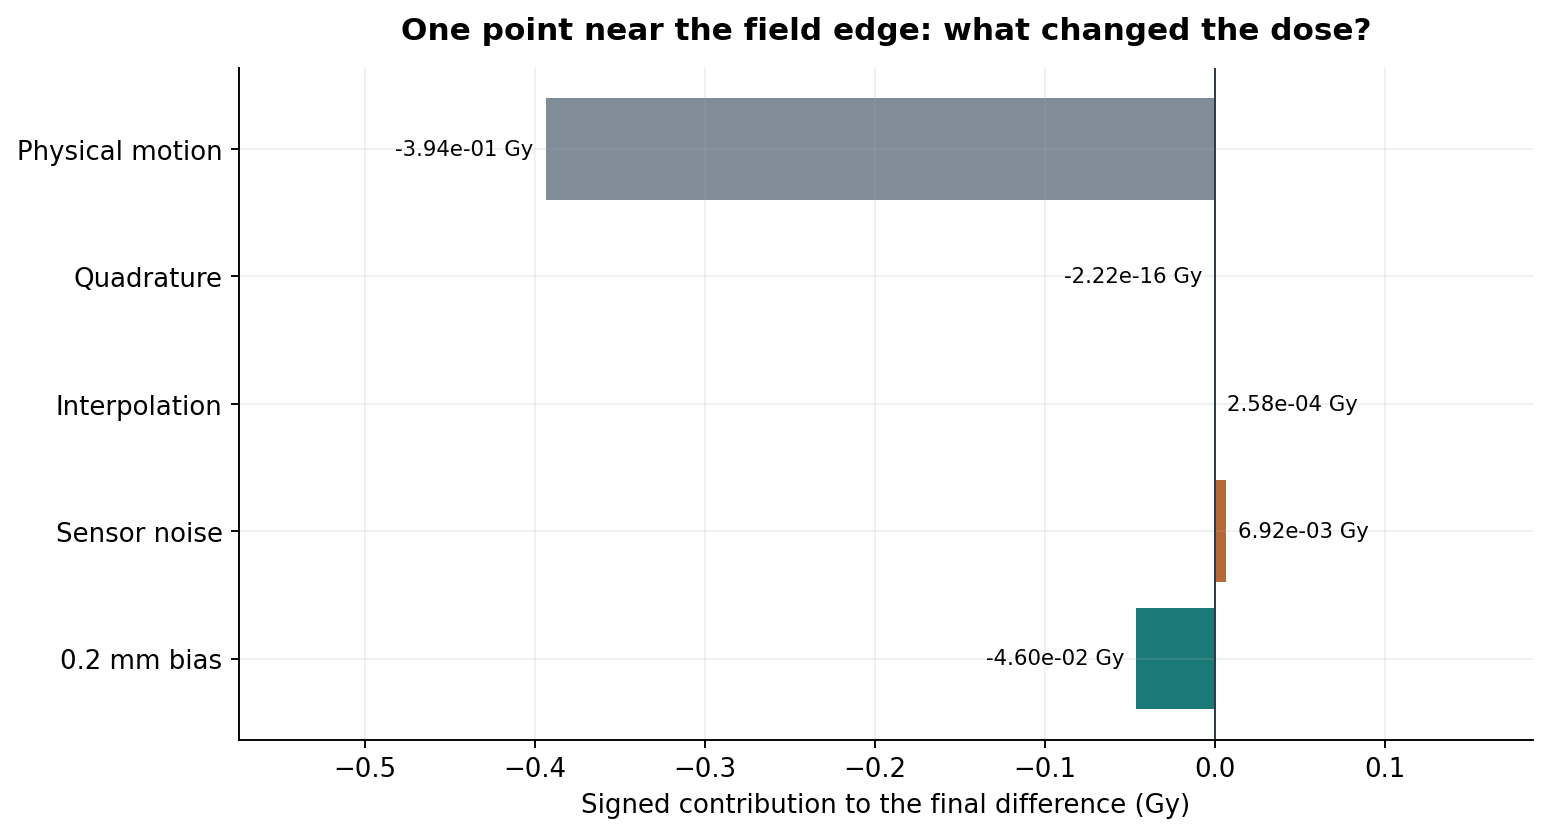

In [10]:
t = np.linspace(0, 8, 1601)
points = np.array([0.0, 6.0, 10.0])
x = motion(t)[0]

moving_dose = accumulated_dose(t, x, points)
static_dose = 8 * dose_rate(points)

for i in range(len(points)):
    print("r = %.1f mm, stationary = %.4f Gy, moving = %.4f Gy" % (
        points[i], static_dose[i], moving_dose[i]))

display(Image(filename=str(root / "figures" / "error_budget.png")))

The budget is a sequence of signed changes at r = 6 mm. It separates the stationary assumption from interpolation, sensor noise and bias. The order matters for this nonlinear model. The very small quadrature term is partly a consequence of the smooth full-period setup.

For a less special integration check, the next table uses 7.3 seconds, which does not complete an integer number of periods.

In [11]:
with (root / "results" / "quadrature_convergence.csv").open() as file:
    rows = list(csv.DictReader(file))

print("intervals    dose error (Gy)    observed order")
for row in rows:
    order = row["observed_order"]
    if order != "":
        order = "%.3f" % float(order)
    print("%-10s   %.7e        %s" % (row["intervals"], float(row["dose_error_gy"]), order))

intervals    dose error (Gy)    observed order
16           7.0290561e-03        
32           1.7451839e-03        2.010
64           4.3441258e-04        2.006
128          1.0847470e-04        2.002
256          2.7110548e-05        2.000
512          6.7771277e-06        2.000


## 5. Follow dose error into a response model

For an illustrative acute exposure, the LQ model is $S(D)=e^{-\alpha D-\beta D^2}$. Its derivative is $S'(D)=-(\alpha+2\beta D)S(D)$. A small dose error therefore produces approximately $S'(D)\Delta D$ error in the surviving fraction.

The surviving fraction is a clonogenic cell-model output. It is not patient survival, and the parameters below are not calibrated to a particular tissue.

Original model response: 0.486752
Actual response change: -0.006108
First-order estimate:   -0.006133


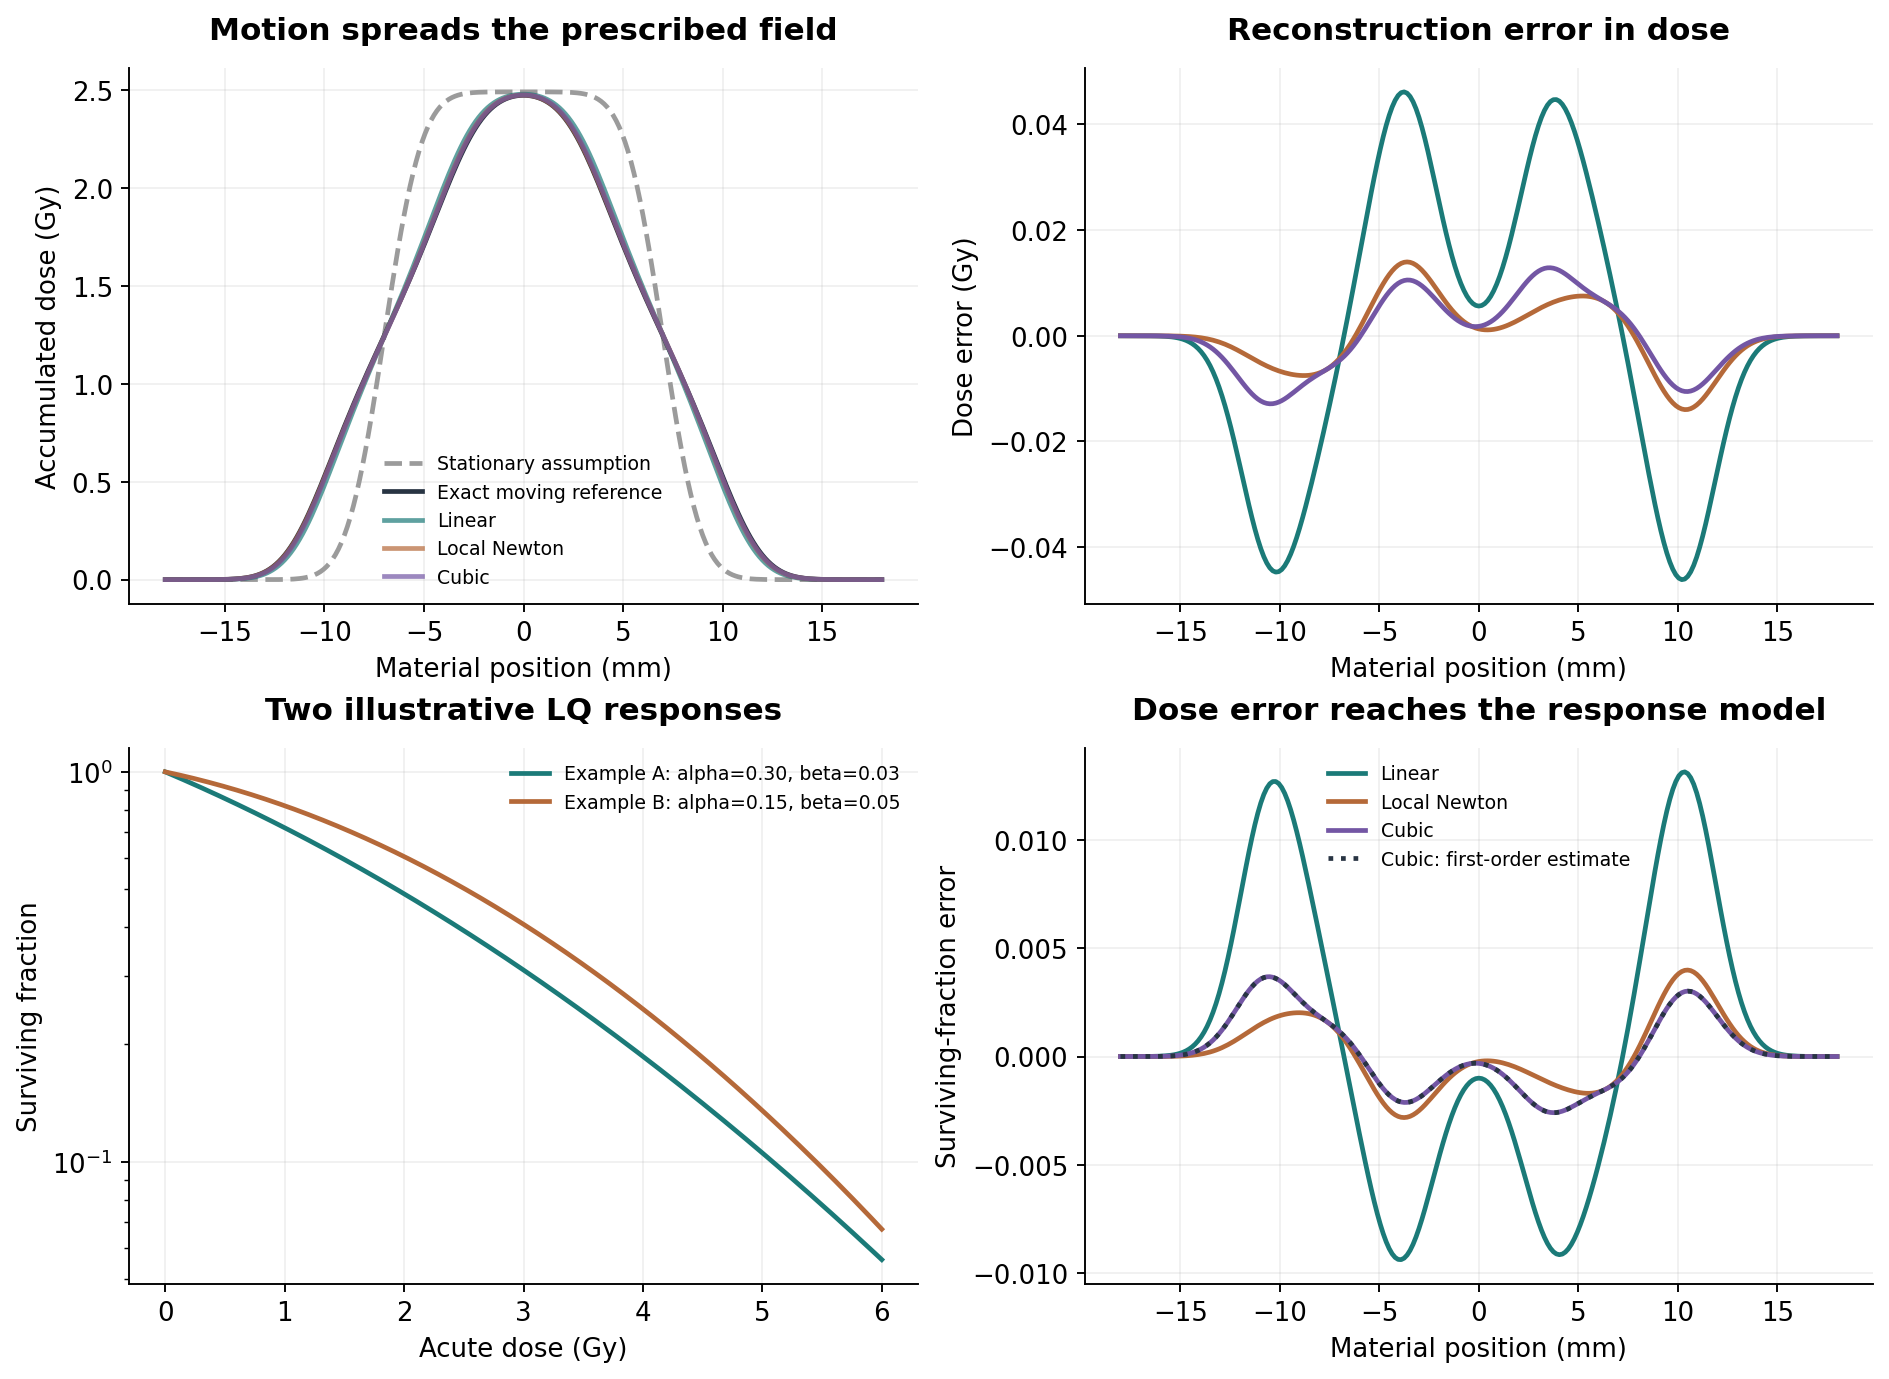

In [12]:
d = 2.0
change = 0.03
alpha = 0.30
beta = 0.03

s = survival(d, alpha, beta)
s_changed = survival(d + change, alpha, beta)
slope = -(alpha + 2 * beta * d) * s

print("Original model response: %.6f" % s)
print("Actual response change: %.6f" % (s_changed - s))
print("First-order estimate:   %.6f" % (slope * change))

display(Image(filename=str(root / "figures" / "dose_and_survival.png")))

## 6. Separate biological states, then Arnoldi

The second biology example is independent of the LQ curve. Let H mean no modeled damage, R repairable damage, and I irreversible damage. After exposure, $H'=rR$, $R'=-(r+\ell)R$, and $I'=\ell R$. The populations sum to one.

Stacking forty locations gives 120 states. One implicit-Euler step solves $(I-\Delta tK)u_{n+1}=u_n$. This is where Arnoldi and GMRES enter. The matrix is small and block diagonal, so a direct solve is the useful baseline; the point here is to inspect residuals, conditioning and orthogonality.

In [13]:
doses = np.linspace(0, 3, 40)
a, initial, k, rates, death = repair_system(doses, dt_min=60)

estimate, history = gmres_steps(a, initial, max_steps=35)
direct = np.linalg.solve(a, initial)
exact_ode = repair_exact(initial, rates, death, 60)

residual = np.linalg.norm(initial - a @ estimate) / np.linalg.norm(initial)
solver_error = np.linalg.norm(estimate - direct) / np.linalg.norm(direct)
time_error = np.linalg.norm(direct - exact_ode) / np.linalg.norm(exact_ode)

print("Relative solver residual: %.3e" % residual)
print("Relative solver error:    %.3e" % solver_error)
print("Relative time-step error: %.3e" % time_error)
print("Arnoldi steps:", len(history))
print("Condition number: %.4f" % np.linalg.cond(a))

states = estimate.reshape(-1, 3)
print("Largest population-sum error: %.3e" % np.max(np.abs(states.sum(axis=1) - 1)))

Relative solver residual: 3.903e-13
Relative solver error:    1.176e-13
Relative time-step error: 9.076e-02
Arnoldi steps: 19
Condition number: 7.7443
Largest population-sum error: 1.776e-15


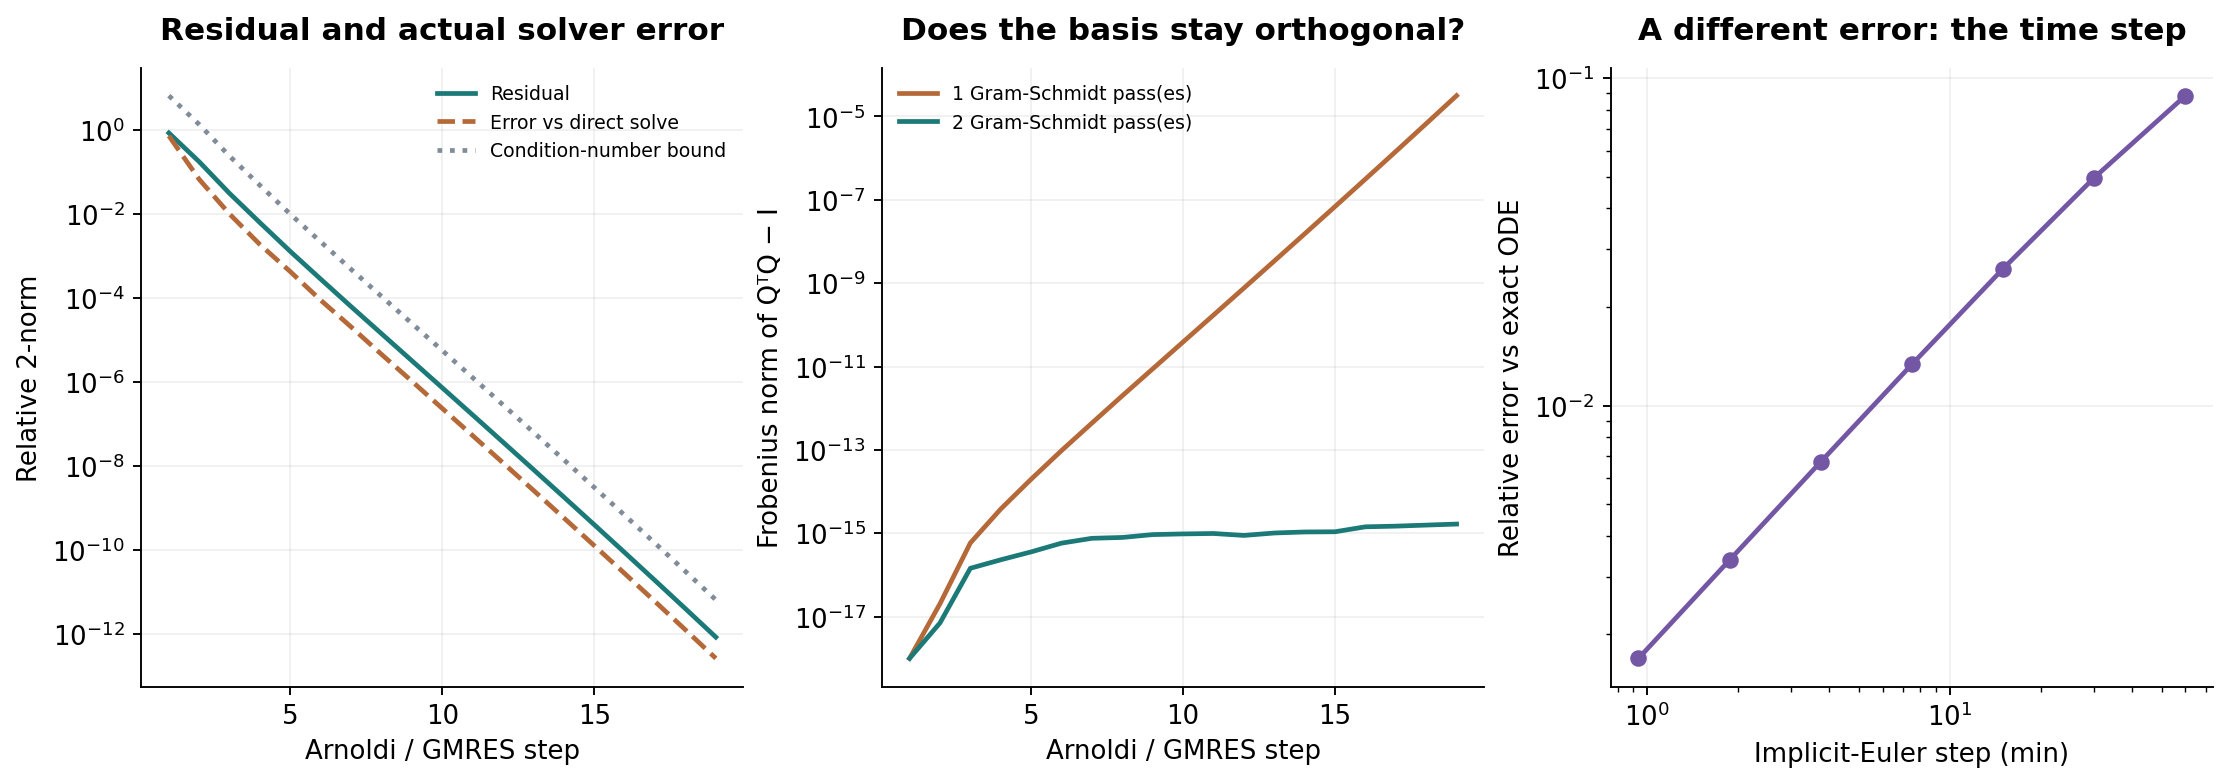

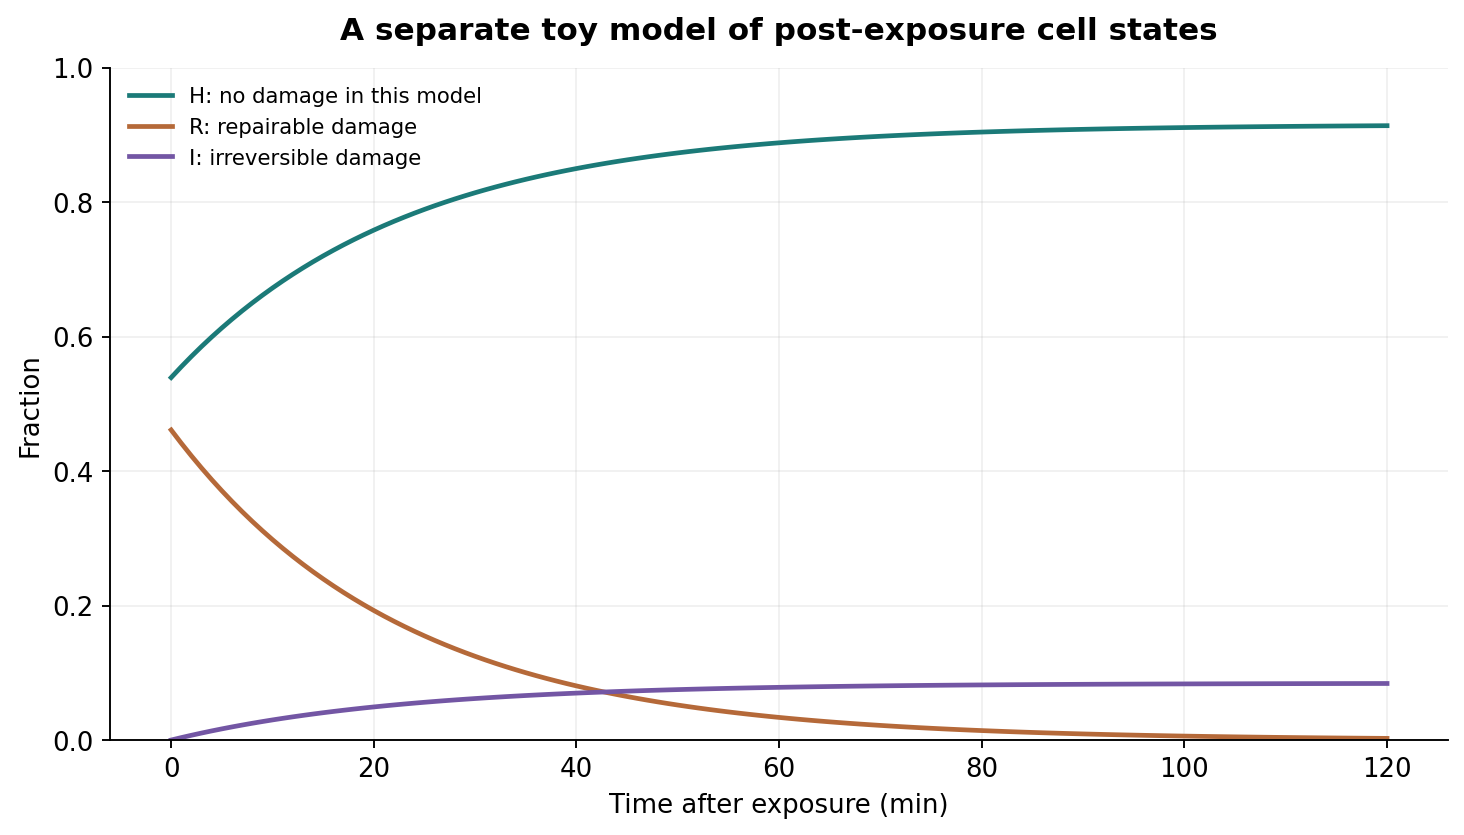

In [14]:
display(Image(filename=str(root / "figures" / "arnoldi_errors.png")))
display(Image(filename=str(root / "figures" / "repair_states.png")))

The plots above use the dose profile from the main experiment; the small code example uses a simpler 0-to-3 Gy range. Both show the distinction between solving a discrete equation accurately and approximating the continuous model accurately.

`gmres_steps` can run one or two Gram-Schmidt passes. The saved experiment records actual residuals, projected residuals, forward errors, orthogonality loss, and the Arnoldi relation. These are separate diagnostics.

## Things to try next

1. In the interpolation example, add a known sensor offset and compare it with independent noise. Does averaging make both errors disappear?
2. Compare natural and not-a-knot spline boundary conditions on the same samples. Report full-interval and interior errors.
3. Build a least-squares smoothing fit and compare it with interpolation using new noise realizations.
4. In GMRES, switch `reorthogonalize=False` and inspect the basis error. Then halve the biological time step separately.
5. Replace the exact periodic trajectory with a documented irregular trace, while keeping a reference calculation.

Equations, units, limitations, and sources are in [model_notes.md](model_notes.md). The tests can be run with `python -m unittest discover -s tests -v`.